# Theo dõi huấn luyện coursework

Đọc `outputs/runs/lan_*/config.json`, `history.json` và `summary.json`; không nạp checkpoint, dataset hoặc chạy model.
Biểu đồ cập nhật sau **mỗi epoch hoàn tất** khi script train ghi history. Epoch đang chạy chưa có số liệu mới.
Smoke mini-epoch được loại khỏi biểu đồ. Kết quả ResNet cũ chỉ là lịch sử; chưa có lượt ConvNeXt.
Chạy **Run All** để xem; chọn kernel `.venv` của workspace.


In [1]:
import json
import math
import time
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import HTML, clear_output, display

# Works from the workspace root or the project directory.
PROJECT = Path.cwd()
if (PROJECT / 'coursework_vit_classification').is_dir():
    PROJECT = PROJECT / 'coursework_vit_classification'
if not (PROJECT / 'src/config.py').exists():
    raise FileNotFoundError('Open the notebook from the workspace or coursework directory.')
RUNS = PROJECT / 'outputs/runs'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})


## Chọn lượt chạy

`RUN_NAMES=[]` đọc mọi lượt đủ history; ví dụ `['lan_9', 'lan_10']` chỉ xem hai lượt.
Mặc định hiển thị resource probe và ResNet lịch sử, có nhãn rõ ràng để kiểm tra log hiện có.
Đặt hai cờ dưới thành `False` khi chỉ muốn xem pilot/final của ConvNeXt và ViT hiện tại.
Không trộn resource probe với pilot/final khi kết luận model nào tốt hơn; các lượt phải cùng protocol.


In [2]:
RUN_NAMES = []
INCLUDE_RESOURCE_PROBES = True
INCLUDE_HISTORICAL_MODELS = True


In [3]:
def load_runs():
    runs, notices = [], []
    folders = sorted(RUNS.glob('lan_*'), key=lambda p: int(p.name[4:]) if p.name[4:].isdigit() else 10**9)
    for folder in folders:
        if RUN_NAMES and folder.name not in RUN_NAMES:
            continue
        try:
            settings = json.loads((folder / 'config.json').read_text(encoding='utf-8'))
            if settings.get('phase') == 'smoke':
                continue
            if not INCLUDE_RESOURCE_PROBES and settings.get('purpose') == 'resource_probe':
                continue
            if not INCLUDE_HISTORICAL_MODELS and settings.get('model') not in ('convnext_base', 'vit_b_16'):
                continue
            history = json.loads((folder / 'history.json').read_text(encoding='utf-8'))
            if not isinstance(history, list):
                raise ValueError('history must be a list')
            rows = [row for row in history if isinstance(row, dict) and isinstance(row.get('epoch'), int) and row['epoch'] >= 1]
            if not rows:
                notices.append(folder.name + ': no completed epoch yet')
                continue
            summary = {}
            if (folder / 'summary.json').exists():
                summary = json.loads((folder / 'summary.json').read_text(encoding='utf-8'))
            runs.append(dict(name=folder.name, settings=settings, history=rows, summary=summary))
        except (OSError, ValueError, TypeError) as error:
            notices.append(f'{folder.name}: {error}')
    found = {folder.name for folder in folders}
    notices.extend(name + ': folder not found' for name in RUN_NAMES if name not in found)
    return runs, notices


def draw_dashboard():
    runs, notices = load_runs()
    print('Updated:', time.strftime('%Y-%m-%d %H:%M:%S'), '| saved epoch metrics; no batch tracking')
    for notice in notices:
        print(notice)
    if not runs:
        print('No full-epoch history matches the filters. Wait for an epoch or adjust the filters.')
        return

    columns = ['Run', 'Model', 'Strategy', 'Phase / purpose', 'Saved epoch / target', 'Best val acc', 'Last train / val acc', 'Epoch time', 'Recorded status']
    table = '<table><thead><tr>' + ''.join('<th>' + x + '</th>' for x in columns) + '</tr></thead><tbody>'
    for run in runs:
        settings, history = run['settings'], run['history']
        last = history[-1]
        valid = [r['val_accuracy'] for r in history if isinstance(r.get('val_accuracy'), (int, float)) and math.isfinite(r['val_accuracy'])]
        def percent(value):
            return f'{100*value:.2f}%' if isinstance(value, (int, float)) and math.isfinite(value) else '—'
        values = [run['name'], settings.get('model'), settings.get('strategy'),
                  f"{settings.get('phase')} / {settings.get('purpose', 'experiment')}",
                  f"{last['epoch']} / {settings.get('epochs', '?')}", percent(max(valid)) if valid else '—',
                  f"{percent(last.get('train_accuracy'))} / {percent(last.get('val_accuracy'))}",
                  f"{last['seconds']:.1f}s" if isinstance(last.get('seconds'), (int, float)) else '—',
                  run['summary'].get('status', 'unknown')]
        table += '<tr>' + ''.join('<td>' + escape(str(v)) + '</td>' for v in values) + '</tr>'
    display(HTML(table + '</tbody></table>'))
    print('Status is saved metadata, not a check that the training process is alive.')

    fig, axes = plt.subplots(3, 2, figsize=(14, 12), constrained_layout=True)
    panels = [('train_loss', 'Train loss', 1), ('val_loss', 'Validation loss', 1),
              ('train_accuracy', 'Train accuracy (%)', 100), ('val_accuracy', 'Validation accuracy (%)', 100),
              ('lr', 'Learning rate', 1), ('seconds', 'Train + validation seconds / epoch', 1)]
    colors = plt.get_cmap('tab20')
    for index, run in enumerate(runs):
        settings = run['settings']
        label = f"{run['name']} | {settings.get('model')} {settings.get('experiment')} | {settings.get('phase')}/{settings.get('purpose', 'experiment')} | LR={settings.get('lr')}"
        for ax, (key, title, scale) in zip(axes.flat, panels):
            points = [(r['epoch'], r[key]*scale) for r in run['history']
                      if isinstance(r.get(key), (int, float)) and math.isfinite(r[key])]
            if points:
                x, y = zip(*points)
                ax.plot(x, y, marker='o', markersize=3, label=label, color=colors(index % 20))
    for ax, (key, title, _) in zip(axes.flat, panels):
        ax.set(title=title, xlabel='Completed epoch')
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        if 'accuracy' in key:
            ax.set_ylim(0, 100)
        if not ax.lines:
            ax.text(0.5, 0.5, 'No recorded metric', transform=ax.transAxes, ha='center')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc='outside lower center', fontsize=8)
    plt.show()
    plt.close(fig)


## Biểu đồ hiện tại

Train và validation tách riêng để giảm số đường trên mỗi biểu đồ; mỗi run giữ cùng màu.
Accuracy hiển thị theo phần trăm. Không có đường test theo epoch vì test được giữ cho đánh giá cuối.
Lượt mới hoàn tất một epoch chỉ xuất hiện một điểm; không suy ra hội tụ từ một điểm.
Chạy lại cell dưới để đọc history mới nhất trong khi train chạy ở terminal khác.


Updated: 2026-11-23 20:04:23 | saved epoch metrics; no batch tracking
lan_20: [Errno 2] No such file or directory: 'c:\\Users\\hovan\\OneDrive\\Desktop\\deep-learning-cousework\\deep-learning-cousework\\coursework_vit_classification\\outputs\\runs\\lan_20\\history.json'


Run,Model,Strategy,Phase / purpose,Saved epoch / target,Best val acc,Last train / val acc,Epoch time,Recorded status
lan_12,convnext_base,freeze,tuning / experiment,5 / 5,80.64%,87.60% / 80.64%,336.0s,completed
lan_13,convnext_base,freeze,tuning / experiment,5 / 5,80.78%,85.37% / 80.78%,337.0s,completed
lan_14,convnext_base,freeze,final / experiment,20 / 20,81.46%,92.77% / 80.94%,341.4s,completed
lan_18,resnet50,fine_tune_layer4,tuning / experiment,5 / 5,76.72%,90.46% / 76.34%,259.8s,completed
lan_19,resnet50,fine_tune_layer4,tuning / experiment,5 / 5,79.10%,92.75% / 77.80%,216.2s,completed
lan_21,resnet50,fine_tune_layer4,final / experiment,20 / 20,79.10%,98.97% / 76.82%,207.0s,completed


Status is saved metadata, not a check that the training process is alive.


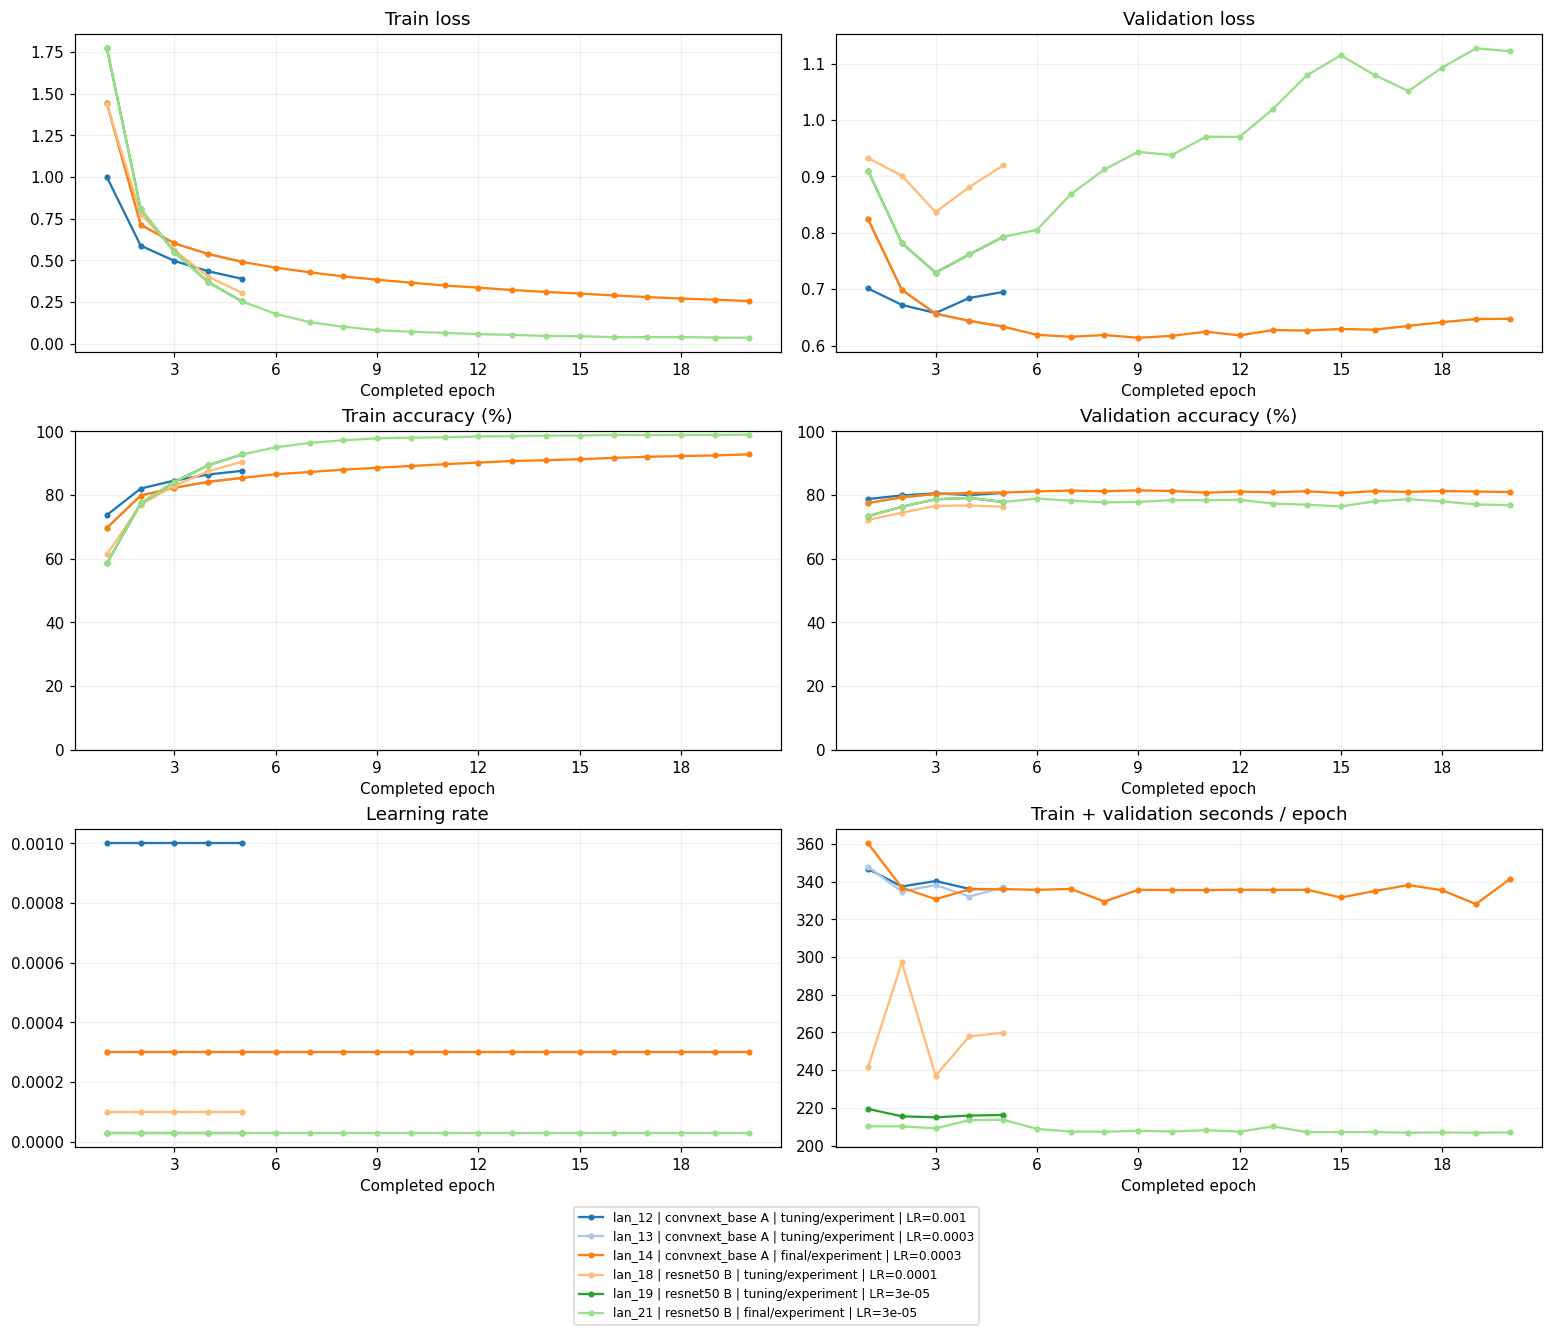

In [4]:
draw_dashboard()


## Tự cập nhật khi cần

Đặt `AUTO_REFRESH=True`, chạy cell dưới để cập nhật mỗi 15 giây, tối đa 60 lần (~15 phút).
Dùng **Interrupt** để dừng theo dõi, không ảnh hưởng tiến trình train ở terminal riêng.
Theo dõi chỉ đọc JSON, không ghi log hoặc thay config huấn luyện. Không có metric từng batch.


In [5]:
AUTO_REFRESH = False
REFRESH_SECONDS = 15
MAX_REFRESHES = 60

if AUTO_REFRESH:
    try:
        for refresh in range(MAX_REFRESHES):
            clear_output(wait=True)
            draw_dashboard()
            if refresh + 1 < MAX_REFRESHES:
                time.sleep(REFRESH_SECONDS)
    except KeyboardInterrupt:
        print('Monitoring stopped; training was not interrupted.')
